# COM7022 Machine Learning: Task 1, Clustering e-commerce products

Student ID: **[YOUR STUDENT ID]**

Goal: group the products in the sales dataset by their characteristics and sales performance using K-Means, Hierarchical clustering and DBSCAN, then compare the models and describe the clusters.

## 1. Libraries and settings

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", font_scale=0.95)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 150)
pd.set_option("display.max_colwidth", 22)

SEED = 42
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
COLOURS = ["#2f6db5", "#e07b39", "#3a9d5d", "#c4453c", "#8064a2", "#7f7f7f"]

## 2. Loading and understanding the data

In [2]:
df_raw = pd.read_csv("assignquestion.csv", encoding="utf-8-sig")
print("Shape:", df_raw.shape)
df_raw.head(3)

Shape: (1000, 10)


,Item_Name,details,Catatory,price,priceWithCurrency,available,text,sold,lastUpdated,itemLocation
0,Dior,Christian Dior Sau...,Eau de Parfum,84.99,US $84.99/ea,10.0,More than 10 avail...,NaN,"May 24, 2024 10:03...","Allen Park, Michig..."
1,AS SHOW,A-v-entus Eau de P...,Eau de Parfum,NaN,US $109.99,8.0,8 available / 48 sold,48.0,"May 23, 2024 23:07...","Atlanta, Georgia, ..."
2,Unbranded,HOGO BOSS cologne ...,Eau de Toilette,100.00,US $100.00,10.0,More than 10 avail...,27.0,"May 22, 2024 21:55...","Dearborn, Michigan..."


In [3]:
df_raw.info()
print("\nDuplicate rows:", df_raw.duplicated().sum())
print("Unique brands:", df_raw["Item_Name"].nunique())
print("Unique category labels:", df_raw["Catatory"].nunique())
print("Unique locations:", df_raw["itemLocation"].nunique())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Item_Name          999 non-null    str    
 1   details            1000 non-null   str    
 2   Catatory           997 non-null    str    
 3   price              995 non-null    float64
 4   priceWithCurrency  999 non-null    str    
 5   available          889 non-null    float64
 6   text               997 non-null    str    
 7   sold               992 non-null    float64
 8   lastUpdated        947 non-null    str    
 9   itemLocation       1000 non-null   str    
dtypes: float64(3), str(7)
memory usage: 78.3 KB

Duplicate rows: 0
Unique brands: 246
Unique category labels: 63
Unique locations: 276


In [4]:
df_raw.describe().round(2)

,price,available,sold
count,995.00,889.00,992.00
mean,46.43,20.05,775.25
std,35.55,61.55,3211.43
min,3.00,2.00,1.00
25%,22.99,5.00,14.00
50%,35.71,10.00,49.50
75%,59.00,10.00,324.75
max,259.09,842.00,54052.00


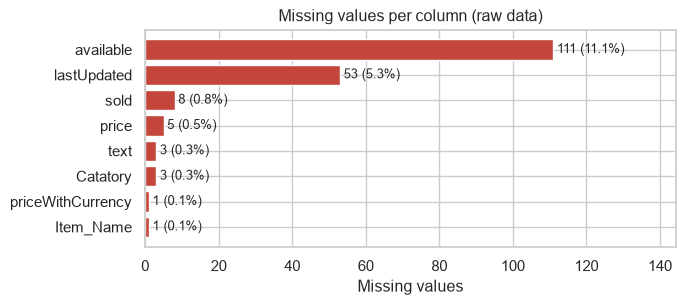

In [5]:
missing = df_raw.isna().sum()
missing = missing[missing > 0].sort_values()

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(missing.index, missing.values, color="#c4453c")
for i, v in enumerate(missing.values):
    ax.text(v + 1, i, f"{v} ({v / len(df_raw):.1%})", va="center", fontsize=9)
ax.set_xlabel("Missing values")
ax.set_title("Missing values per column (raw data)")
ax.set_xlim(0, missing.max() * 1.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig01_missing_values.png", dpi=150)
plt.show()

The `text` and `priceWithCurrency` columns repeat information from other columns, so they can be used to fill some of the gaps.

In [6]:
print(df_raw["text"].str.replace(r"[\d,]+", "N", regex=True).value_counts(), "\n")
print(df_raw["priceWithCurrency"].str.extract(r"^(\D+)")[0].value_counts(), "\n")
print(df_raw["Catatory"].value_counts().head(12))

text
N available / N sold                                     590
More than N available / N sold                           296
Limited quantity available / N sold                       59
Last One / N sold                                         47
More than N lots available (N items per lot) / N sold      2
N available                                                2
More than N available                                      1
Name: count, dtype: int64 

0
US $    996
C $       3
Name: count, dtype: int64 

Catatory
Eau de Toilette    444
Eau de Parfum      285
Eau de Cologne      56
Perfume             50
Fragrances          32
Eau De Parfum       15
Parfum              13
Eau de Perfume      10
Eau De Toilette      9
Gift Sets            6
Cologne              5
PARFUM               4
Name: count, dtype: int64


## 3. Data cleaning

In [7]:
df = df_raw.rename(columns={"Item_Name": "brand", "Catatory": "category_raw"}).copy()

price_text = df["priceWithCurrency"].fillna("").str.replace(",", "")
df["price"] = df["price"].fillna(price_text.str.extract(r"([\d.]+)")[0].astype(float))
cad = price_text.str.startswith("C")
df.loc[cad, "price"] = df.loc[cad, "price"] * 0.73

stock_text = df["text"].fillna("").str.replace(",", "")
df["sold"] = df["sold"].fillna(stock_text.str.extract(r"(\d+) sold")[0].astype(float))
df["sold"] = df["sold"].fillna(0)
df.loc[stock_text.str.startswith("Last One"), "available"] = 1
df["available"] = df["available"].fillna(df["available"].median())

updated = pd.to_datetime(df["lastUpdated"].str[:-4], format="%b %d, %Y %H:%M:%S", errors="coerce")
df["days_since_update"] = (updated.max() - updated).dt.total_seconds() / 86400
df["days_since_update"] = df["days_since_update"].fillna(df["days_since_update"].median())

details = df["details"].str.lower()
ml = details.str.extract(r"(\d+(?:\.\d+)?)\s*ml")[0].astype(float)
oz = details.str.extract(r"(\d+(?:\.\d+)?)\s*(?:fl\.?\s*)?oz")[0].astype(float)
df["size_ml"] = ml.fillna(oz * 29.57)
print("Size found in title for", f"{df['size_ml'].notna().mean():.1%}", "of listings")
df["size_ml"] = df["size_ml"].fillna(df["size_ml"].median())

df["brand"] = df["brand"].fillna("Unbranded").str.strip()
df["country"] = df["itemLocation"].str.split(",").str[-1].str.strip()
df["ships_from_us"] = (df["country"] == "United States").astype(int)

print("Prices converted from CAD:", cad.sum())
print("'Last One' listings set to 1 available:", stock_text.str.startswith("Last One").sum())
print("Latest update in data:", updated.max())
print("\nMissing values after cleaning:")
print(df[["price", "sold", "available", "days_since_update", "size_ml", "brand"]].isna().sum())

Size found in title for 93.7% of listings
Prices converted from CAD: 3
'Last One' listings set to 1 available: 47
Latest update in data: 2024-05-24 10:27:08

Missing values after cleaning:
price                0
sold                 0
available            0
days_since_update    0
size_ml              0
brand                0
dtype: int64


### Grouping the category labels

category
Eau de Toilette         463
Eau de Parfum/Parfum    394
Other                    73
Cologne                  70
Name: count, dtype: int64 

country
United States    912
Hong Kong         52
Canada            11
China             11
Taiwan             6
India              3
Name: count, dtype: int64


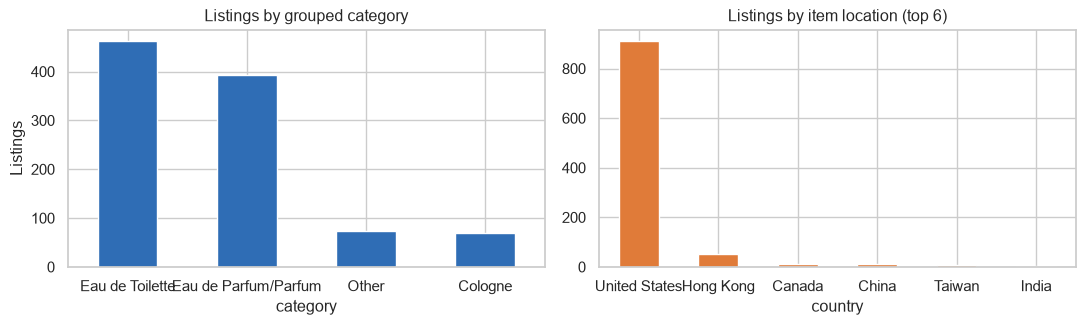

In [8]:
cat = df["category_raw"].fillna("").str.lower()
rules = [cat.str.contains("toil|edt"),
         cat.str.contains("parf|perf|elixir|extrait"),
         cat.str.contains("cologne|edc")]
df["category"] = np.select(rules, ["Eau de Toilette", "Eau de Parfum/Parfum", "Cologne"], default="Other")

print(df["category"].value_counts(), "\n")
print(df["country"].value_counts().head(6))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
df["category"].value_counts().plot(kind="bar", ax=axes[0], color=COLOURS[0], rot=0)
axes[0].set_title("Listings by grouped category")
axes[0].set_ylabel("Listings")
df["country"].value_counts().head(6).plot(kind="bar", ax=axes[1], color=COLOURS[1], rot=0)
axes[1].set_title("Listings by item location (top 6)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig02_categories_locations.png", dpi=150)
plt.show()

## 4. Outliers and skewness

In [9]:
num_cols = ["price", "sold", "available", "days_since_update", "size_ml"]

rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    rows.append([col, df[col].median(), df[col].max(), n_out, df[col].skew(), np.log1p(df[col]).skew()])

outlier_table = pd.DataFrame(rows, columns=["feature", "median", "max", "IQR outliers", "skew raw", "skew log1p"])
outlier_table.round(2)

,feature,median,max,IQR outliers,skew raw,skew log1p
0,price,35.70,259.09,54,2.04,0.11
1,sold,48.00,54052.00,138,9.75,0.50
2,available,9.00,842.00,98,8.65,1.58
3,days_since_update,1.75,581.67,132,13.31,1.19
4,size_ml,100.54,1005.38,476,7.56,-2.79


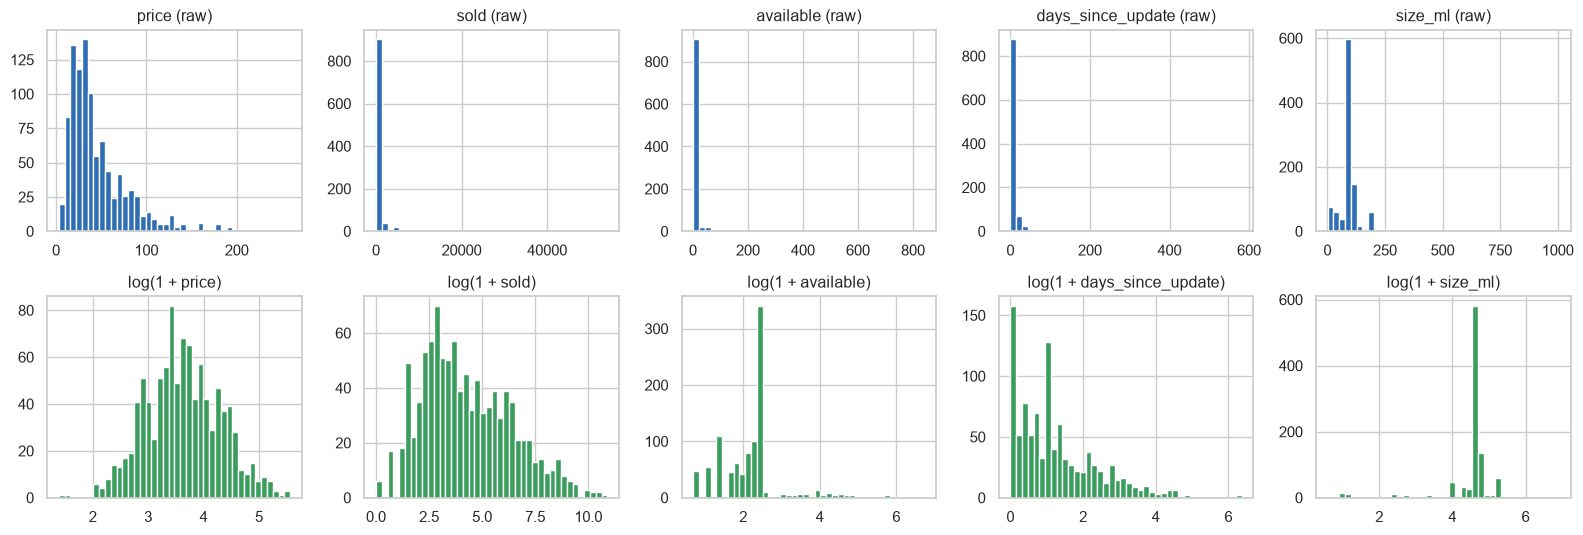

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(16, 5.5))
for i, col in enumerate(num_cols):
    axes[0, i].hist(df[col], bins=40, color=COLOURS[0])
    axes[0, i].set_title(f"{col} (raw)")
    axes[1, i].hist(np.log1p(df[col]), bins=40, color=COLOURS[2])
    axes[1, i].set_title(f"log(1 + {col})")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig03_distributions_raw_vs_log.png", dpi=150)
plt.show()

## 5. Feature selection

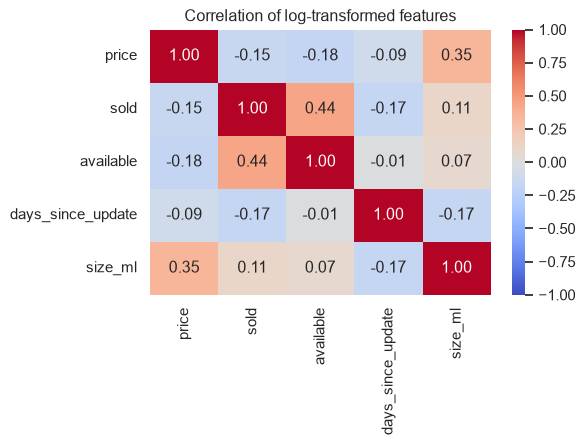

In [11]:
X_log = np.log1p(df[num_cols])

fig, ax = plt.subplots(figsize=(6, 4.6))
sns.heatmap(X_log.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation of log-transformed features")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig04_correlation.png", dpi=150)
plt.show()

Testing whether the one-hot encoded category should go into the distance calculation.

In [12]:
X_std = StandardScaler().fit_transform(X_log)
dummies = pd.get_dummies(df[["category"]], dtype=float)
X_with_cat = np.hstack([X_std, StandardScaler().fit_transform(dummies)])

km_cat = KMeans(n_clusters=4, n_init=20, random_state=SEED).fit(X_with_cat)
print("Silhouette with category dummies:", round(silhouette_score(X_with_cat, km_cat.labels_), 3))
pd.crosstab(km_cat.labels_, df["category"], rownames=["cluster"])

Silhouette with category dummies: 0.355


category,Cologne,Eau de Parfum/Parfum,Eau de Toilette,Other
cluster,,,,
0,0,0,463,0
1,0,394,0,0
2,0,0,0,73
3,70,0,0,0


## 6. Scaling and normalisation

In [13]:
scalers = {"StandardScaler": StandardScaler(), "MinMaxScaler": MinMaxScaler(), "RobustScaler": RobustScaler()}

rows = []
spread = {}
for name, scaler in scalers.items():
    Xs = scaler.fit_transform(X_log)
    spread[name] = Xs.std(axis=0).round(2)
    for k in [3, 4, 5, 6]:
        labels = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(Xs)
        rows.append([name, k, silhouette_score(Xs, labels)])

scaler_table = pd.DataFrame(rows, columns=["scaler", "k", "silhouette"]).pivot(index="scaler", columns="k", values="silhouette")
print(scaler_table.round(3), "\n")
print("Standard deviation of each feature after scaling:")
pd.DataFrame(spread, index=num_cols).T

k                   3      4      5      6
scaler                                    
MinMaxScaler    0.244  0.263  0.267  0.247
RobustScaler    0.780  0.750  0.802  0.800
StandardScaler  0.253  0.246  0.255  0.249 

Standard deviation of each feature after scaling:


,price,sold,available,days_since_update,size_ml
StandardScaler,1.00,1.00,1.00,1.00,1.00
MinMaxScaler,0.16,0.19,0.15,0.17,0.14
RobustScaler,0.73,0.68,1.16,0.75,159.01


In [14]:
X = StandardScaler().fit_transform(X_log)
print(X.shape)
print(pd.DataFrame(X, columns=num_cols).describe().loc[["mean", "std"]].round(2))

(1000, 5)
      price  sold  available  days_since_update  size_ml
mean    0.0   0.0       -0.0               -0.0      0.0
std     1.0   1.0        1.0                1.0      1.0


## 7. Dimensionality reduction with PCA

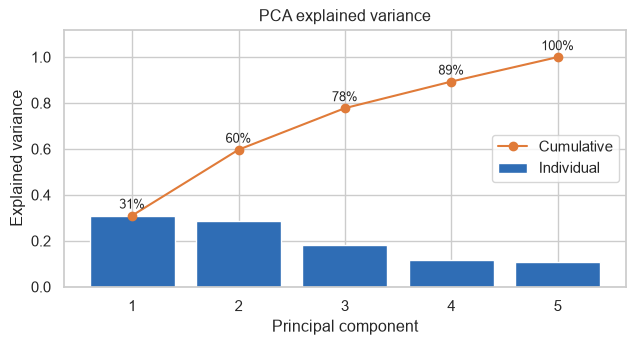

,PC1,PC2
price,-0.30,0.61
sold,0.67,0.09
available,0.65,-0.03
days_since_update,-0.19,-0.42
size_ml,0.09,0.67


In [15]:
pca = PCA(random_state=SEED).fit(X)
ratio = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.bar(range(1, 6), ratio, color=COLOURS[0], label="Individual")
ax.plot(range(1, 6), ratio.cumsum(), marker="o", color=COLOURS[1], label="Cumulative")
for i, v in enumerate(ratio.cumsum()):
    ax.text(i + 1, v + 0.03, f"{v:.0%}", ha="center", fontsize=9)
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance")
ax.set_ylim(0, 1.12)
ax.set_title("PCA explained variance")
ax.legend(loc="center right")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig05_pca_variance.png", dpi=150)
plt.show()

loadings = pd.DataFrame(pca.components_[:2].T, index=num_cols, columns=["PC1", "PC2"])
loadings.round(2)

In [16]:
X_pca = PCA(n_components=2, random_state=SEED).fit_transform(X)

## 8. K-Means

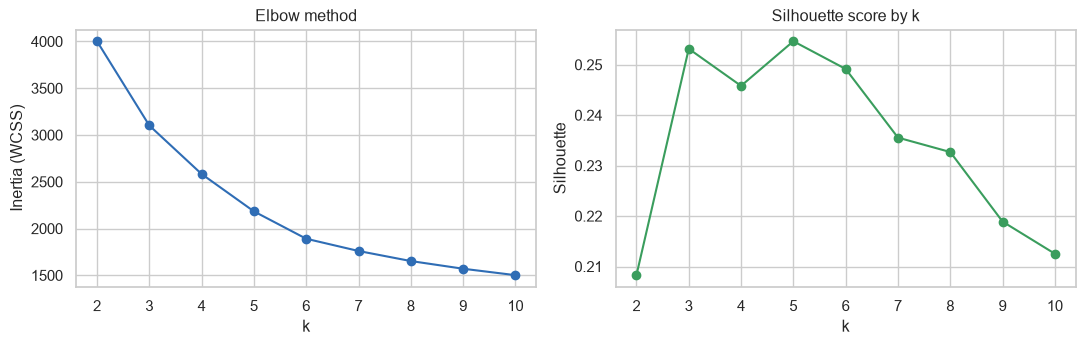

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,4002.637,0.208,1.689,248.678
1,3,3102.087,0.253,1.353,304.993
2,4,2583.498,0.246,1.265,310.540
3,5,2184.183,0.255,1.210,320.690
4,6,1891.641,0.249,1.155,326.670
5,7,1760.799,0.236,1.209,304.457
6,8,1653.248,0.233,1.272,286.879
7,9,1571.102,0.219,1.313,270.355
8,10,1502.367,0.213,1.340,256.089


In [17]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X)
    rows.append([k, km.inertia_, silhouette_score(X, km.labels_),
                 davies_bouldin_score(X, km.labels_), calinski_harabasz_score(X, km.labels_)])
k_table = pd.DataFrame(rows, columns=["k", "inertia", "silhouette", "davies_bouldin", "calinski_harabasz"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(k_table["k"], k_table["inertia"], marker="o", color=COLOURS[0])
axes[0].set_title("Elbow method")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia (WCSS)")
axes[1].plot(k_table["k"], k_table["silhouette"], marker="o", color=COLOURS[2])
axes[1].set_title("Silhouette score by k")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig06_kmeans_elbow_silhouette.png", dpi=150)
plt.show()
k_table.round(3)

Checking how stable each k is when only the random starting point changes (adjusted Rand index against the seed-42 solution).

In [18]:
rows = []
for k in range(3, 7):
    base = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(X)
    scores = [adjusted_rand_score(base, KMeans(n_clusters=k, n_init=1, random_state=s).fit_predict(X)) for s in range(20)]
    rows.append([k, np.mean(scores), np.min(scores)])
pd.DataFrame(rows, columns=["k", "mean ARI", "min ARI"]).round(3)

,k,mean ARI,min ARI
0,3,0.984,0.914
1,4,0.745,0.390
2,5,0.904,0.407
3,6,0.950,0.898


In [19]:
kmeans = KMeans(n_clusters=5, n_init=20, random_state=SEED).fit(X)
df["kmeans"] = kmeans.labels_
print(df["kmeans"].value_counts().sort_index())

kmeans
0    382
1    273
2     71
3    195
4     79
Name: count, dtype: int64


## 9. Hierarchical clustering

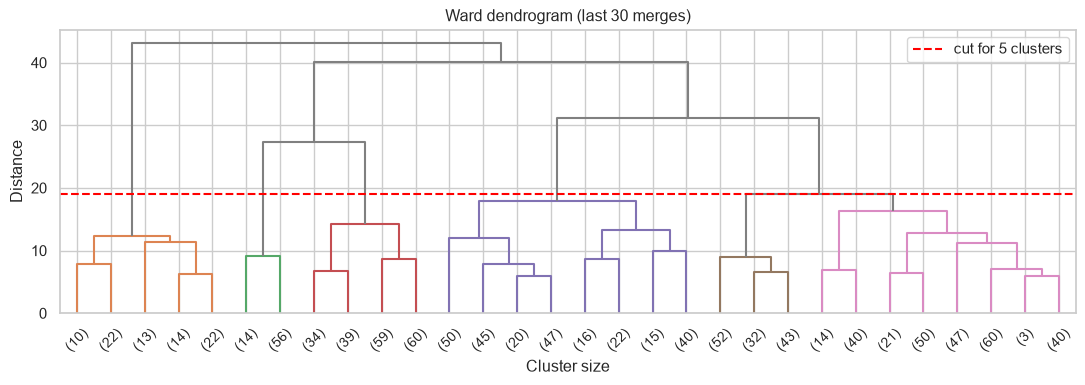

In [20]:
Z = linkage(X, method="ward")

fig, ax = plt.subplots(figsize=(11, 4))
dendrogram(Z, truncate_mode="lastp", p=30, ax=ax, color_threshold=Z[-5, 2], above_threshold_color="grey")
ax.axhline(Z[-5, 2], color="red", linestyle="--", label="cut for 5 clusters")
ax.set_title("Ward dendrogram (last 30 merges)")
ax.set_xlabel("Cluster size")
ax.set_ylabel("Distance")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig07_dendrogram.png", dpi=150)
plt.show()

In [21]:
rows = []
for method in ["ward", "complete", "average"]:
    for k in [3, 4, 5, 6]:
        labels = AgglomerativeClustering(n_clusters=k, linkage=method).fit_predict(X)
        rows.append([method, k, silhouette_score(X, labels), np.bincount(labels).min()])
hc_table = pd.DataFrame(rows, columns=["linkage", "k", "silhouette", "smallest cluster"])
hc_table.round(3)

,linkage,k,silhouette,smallest cluster
0,ward,3,0.231,81
1,ward,4,0.201,81
2,ward,5,0.205,70
3,ward,6,0.168,70
4,complete,3,0.343,76
5,complete,4,0.239,76
6,complete,5,0.185,57
7,complete,6,0.175,3
8,average,3,0.333,1
9,average,4,0.348,1


In [22]:
hier = AgglomerativeClustering(n_clusters=5, linkage="ward").fit(X)
df["hierarchical"] = hier.labels_
print(df["hierarchical"].value_counts().sort_index())

hierarchical
0    402
1    255
2    192
3     81
4     70
Name: count, dtype: int64


## 10. DBSCAN

min_samples: 10 | knee of k-distance curve at eps = 1.38


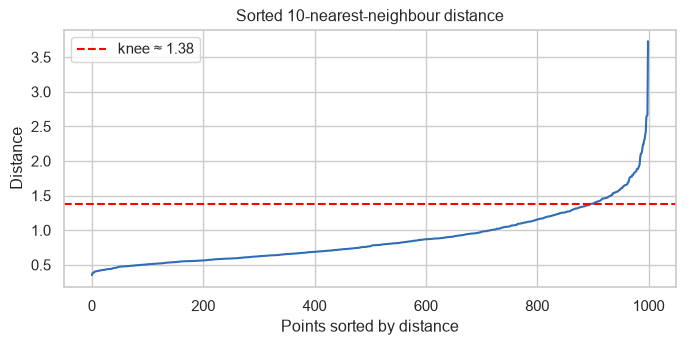

In [23]:
min_samples = 2 * X.shape[1]
nn = NearestNeighbors(n_neighbors=min_samples).fit(X)
k_dist = np.sort(nn.kneighbors(X)[0][:, -1])

line = np.linspace(k_dist[0], k_dist[-1], len(k_dist))
knee = np.argmax(line - k_dist)
print("min_samples:", min_samples, "| knee of k-distance curve at eps =", round(k_dist[knee], 2))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(k_dist, color=COLOURS[0])
ax.axhline(k_dist[knee], color="red", linestyle="--", label=f"knee ≈ {k_dist[knee]:.2f}")
ax.set_title(f"Sorted {min_samples}-nearest-neighbour distance")
ax.set_xlabel("Points sorted by distance")
ax.set_ylabel("Distance")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig08_kdistance.png", dpi=150)
plt.show()

In [24]:
rows = []
for eps in [0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4]:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    mask = labels != -1
    sil = silhouette_score(X[mask], labels[mask]) if n_clusters > 1 else np.nan
    sizes = np.bincount(labels[mask]).tolist() if n_clusters > 0 else []
    rows.append([eps, n_clusters, (labels == -1).mean(), sil, sizes])
pd.DataFrame(rows, columns=["eps", "clusters", "noise share", "silhouette (no noise)", "cluster sizes"]).round(3)

,eps,clusters,noise share,silhouette (no noise),cluster sizes
0,0.8,3,0.296,0.297,"[683, 11, 10]"
1,0.9,3,0.207,0.274,"[760, 16, 17]"
2,1.0,1,0.163,NaN,[837]
3,1.1,3,0.111,0.304,"[867, 10, 12]"
4,1.2,3,0.061,0.269,"[898, 14, 27]"
5,1.3,1,0.040,NaN,[960]
6,1.4,1,0.029,NaN,[971]


In [25]:
dbscan = DBSCAN(eps=1.2, min_samples=min_samples).fit(X)
df["dbscan"] = dbscan.labels_
print(df["dbscan"].value_counts().sort_index())

dbscan
-1     61
 0    898
 1     14
 2     27
Name: count, dtype: int64


## 11. Comparing the three models

In [26]:
def scores(name, labels):
    mask = labels != -1
    n_clusters = len(set(labels[mask]))
    return {"model": name,
            "clusters": n_clusters,
            "noise %": round(100 * (~mask).mean(), 1),
            "silhouette": silhouette_score(X[mask], labels[mask]),
            "davies_bouldin": davies_bouldin_score(X[mask], labels[mask]),
            "calinski_harabasz": calinski_harabasz_score(X[mask], labels[mask]),
            "largest cluster %": round(100 * np.bincount(labels[mask]).max() / mask.sum(), 1)}

comparison = pd.DataFrame([scores("K-Means (k=5)", df["kmeans"].values),
                           scores("Hierarchical Ward (k=5)", df["hierarchical"].values),
                           scores("DBSCAN (eps=1.2)", df["dbscan"].values)])
comparison.round(3)

,model,clusters,noise %,silhouette,davies_bouldin,calinski_harabasz,largest cluster %
0,K-Means (k=5),5,0.0,0.255,1.210,320.690,38.2
1,Hierarchical Ward ...,5,0.0,0.205,1.336,267.370,40.2
2,DBSCAN (eps=1.2),3,6.1,0.269,0.981,84.182,95.6


In [27]:
print("ARI K-Means vs Hierarchical:", round(adjusted_rand_score(df["kmeans"], df["hierarchical"]), 3))
print("ARI K-Means vs DBSCAN:", round(adjusted_rand_score(df["kmeans"], df["dbscan"]), 3))
print("ARI Hierarchical vs DBSCAN:", round(adjusted_rand_score(df["hierarchical"], df["dbscan"]), 3))

ARI K-Means vs Hierarchical: 0.52
ARI K-Means vs DBSCAN: 0.109
ARI Hierarchical vs DBSCAN: 0.11


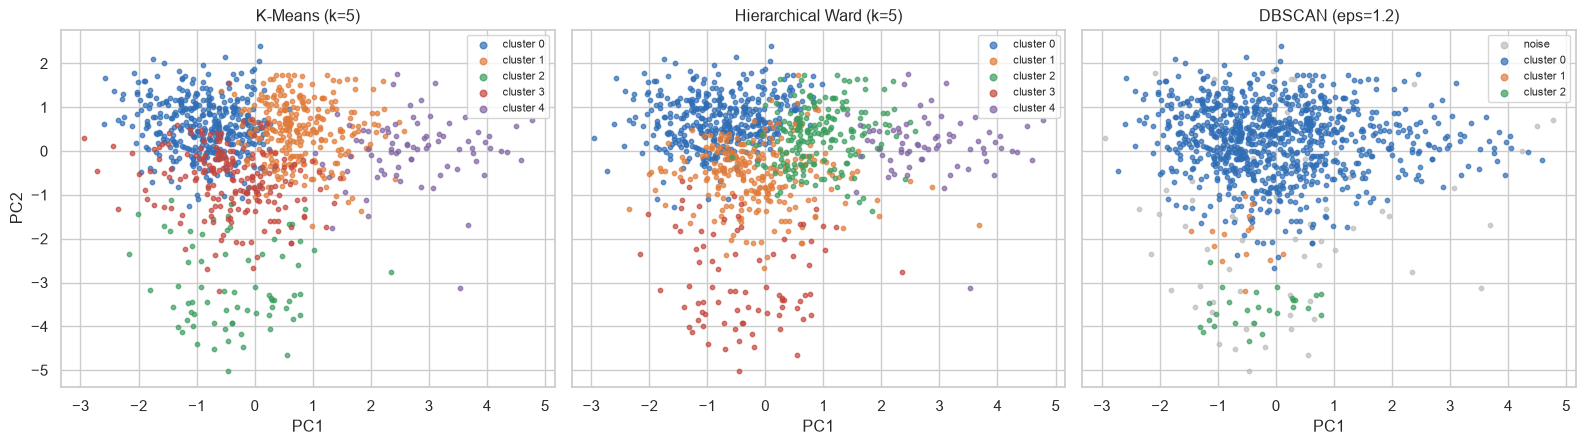

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharex=True, sharey=True)
for ax, col, title in zip(axes, ["kmeans", "hierarchical", "dbscan"],
                          ["K-Means (k=5)", "Hierarchical Ward (k=5)", "DBSCAN (eps=1.2)"]):
    for lab in sorted(df[col].unique()):
        mask = df[col].values == lab
        colour = "#bbbbbb" if lab == -1 else COLOURS[lab]
        name = "noise" if lab == -1 else f"cluster {lab}"
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=10, alpha=0.7, color=colour, label=name)
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.legend(fontsize=8, markerscale=1.5)
axes[0].set_ylabel("PC2")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig09_pca_clusters.png", dpi=150)
plt.show()

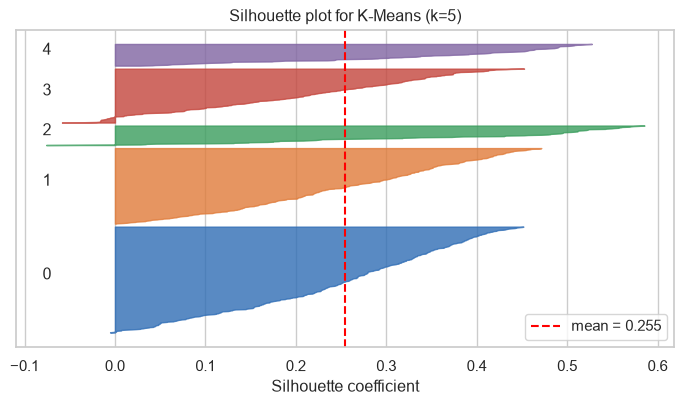

,mean,min,<lambda_0>
kmeans,,,
0,0.245,-0.005,0.008
1,0.255,0.001,0.000
2,0.369,-0.076,0.028
3,0.199,-0.059,0.118
4,0.334,0.027,0.000


In [29]:
sil_values = silhouette_samples(X, df["kmeans"])

fig, ax = plt.subplots(figsize=(7, 4.2))
y_low = 10
for lab in range(5):
    vals = np.sort(sil_values[df["kmeans"] == lab])
    ax.fill_betweenx(np.arange(y_low, y_low + len(vals)), 0, vals, color=COLOURS[lab], alpha=0.8)
    ax.text(-0.08, y_low + len(vals) / 2, str(lab))
    y_low += len(vals) + 10
ax.axvline(sil_values.mean(), color="red", linestyle="--", label=f"mean = {sil_values.mean():.3f}")
ax.set_title("Silhouette plot for K-Means (k=5)")
ax.set_xlabel("Silhouette coefficient")
ax.set_yticks([])
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig10_silhouette_kmeans.png", dpi=150)
plt.show()

pd.Series(sil_values).groupby(df["kmeans"]).agg(["mean", "min", lambda s: (s < 0).mean()]).round(3)

## 12. Profiling the K-Means clusters

In [30]:
df["revenue"] = df["price"] * df["sold"]

profile = df.groupby("kmeans").agg(listings=("price", "size"),
                                   median_price=("price", "median"),
                                   median_sold=("sold", "median"),
                                   median_available=("available", "median"),
                                   median_days_since_update=("days_since_update", "median"),
                                   median_size_ml=("size_ml", "median"),
                                   ships_from_us=("ships_from_us", "mean"),
                                   revenue=("revenue", "sum"))
profile["listing share %"] = 100 * profile["listings"] / len(df)
profile["revenue share %"] = 100 * profile["revenue"] / profile["revenue"].sum()
profile.round(2).T

kmeans,0,1,2,3,4
listings,382.00,273.00,71.00,195.00,79.00
median_price,49.99,32.98,15.95,31.95,25.81
median_sold,16.00,400.00,32.00,31.00,993.00
median_available,5.00,10.00,8.00,10.00,84.00
median_days_since_update,1.60,0.61,3.78,15.83,1.09
median_size_ml,100.27,100.54,2.50,100.00,100.54
ships_from_us,0.85,0.96,1.00,0.90,1.00
revenue,943595.13,20653502.76,296229.54,729104.33,3835626.21
listing share %,38.20,27.30,7.10,19.50,7.90
revenue share %,3.57,78.06,1.12,2.76,14.50


In [31]:
pd.crosstab(df["kmeans"], df["category"], normalize="index").mul(100).round(1)

category,Cologne,Eau de Parfum/Parfum,Eau de Toilette,Other
kmeans,,,,
0,5.8,46.6,36.4,11.3
1,7.0,26.7,60.4,5.9
2,5.6,66.2,22.5,5.6
3,8.2,42.6,44.1,5.1
4,11.4,16.5,72.2,0.0


In [32]:
for lab in range(5):
    top = df.loc[df["kmeans"] == lab, "brand"].value_counts().head(4)
    print(lab, ", ".join(f"{b} ({n})" for b, n in top.items()))

0 Giorgio Armani (28), Paco Rabanne (24), Dolce&Gabbana (18), Unbranded (17)
1 Giorgio Armani (20), Unbranded (15), Armaf (12), Versace (10)
2 Creed (6), Yves Saint Laurent (5), Dolce & Gabbana (4), CHANEL (4)
3 Ralph Lauren (9), Unbranded (8), Giorgio Armani (8), Paco Rabanne (8)
4 Ralph Lauren (5), Liz Claiborne (5), Armaf (4), Montblanc (3)


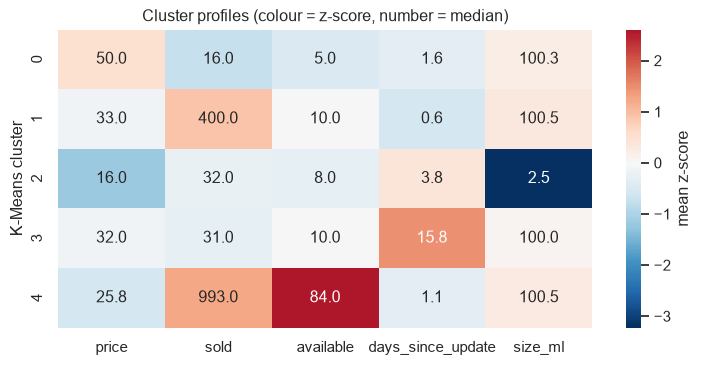

In [33]:
z = pd.DataFrame(X, columns=num_cols).groupby(df["kmeans"]).mean()

fig, ax = plt.subplots(figsize=(7.5, 3.8))
sns.heatmap(z, annot=profile[["median_price", "median_sold", "median_available",
                               "median_days_since_update", "median_size_ml"]].round(1).values,
            fmt="", cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "mean z-score"})
ax.set_title("Cluster profiles (colour = z-score, number = median)")
ax.set_ylabel("K-Means cluster")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig11_cluster_profiles.png", dpi=150)
plt.show()

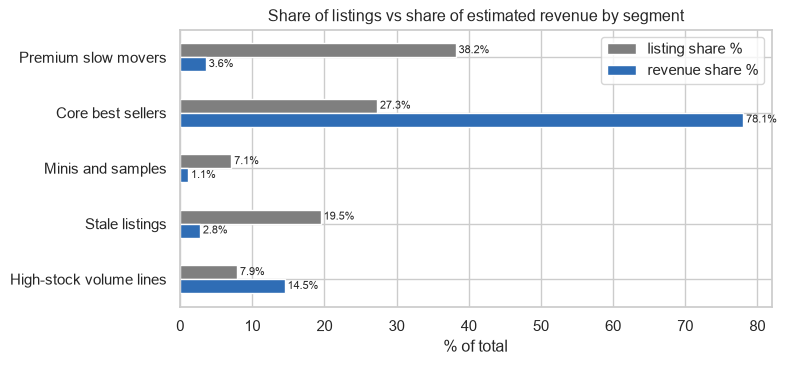

In [34]:
segment_names = {0: "Premium slow movers", 1: "Core best sellers", 2: "Minis and samples", 3: "Stale listings", 4: "High-stock volume lines"}
share = profile[["listing share %", "revenue share %"]].rename(index=segment_names)

ax = share.plot(kind="barh", figsize=(8, 3.8), color=[COLOURS[5], COLOURS[0]])
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", fontsize=8, padding=2)
ax.set_xlabel("% of total")
ax.set_ylabel("")
ax.set_title("Share of listings vs share of estimated revenue by segment")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig12_segment_share.png", dpi=150)
plt.show()

In [35]:
df.to_csv("clustered_products.csv", index=False)